# 수험번호를 반드시 입력하세요!

**문제를 시작하기 전에, 바로 아래 셀의 `student_id`에 본인의 수험번호를 입력하고 실행하세요.**

예: `student_id = '001234'` — 앞자리 0도 포함하여 따옴표 안에 입력하세요.


In [1]:
# 본인의 수험번호를 따옴표 안에 입력하세요. 예: '001234'
student_id = '000000'
if not student_id or not student_id.isascii() or not student_id.isdigit():
    raise ValueError('수험번호를 숫자로만 입력하세요. 앞자리 0도 그대로 적습니다.')
print('수험번호:', student_id)


수험번호: 000000


## 코드 작성 안내
- 답안 작성과 관련 있는 셀은 앞쪽에 `답안 작성 셀`로 시작하는 마크다운 셀이 있습니다.
- 수정이 불가한 셀에는 `# 수정 금지`로 표시가 되어있습니다. 해당 주석이 있는 셀의 코드는 절대 수정하지 마세요.
- 수정 가능한 셀은 `# 수정 가능`으로 표시가 되어있습니다. 다만 셀 안에서 함수명 등 변경하면 안되는 부분도 있으니, 그런 경우 해당 셀 혹은 문항의 안내를 참고하세요.

# 문제 1-1.

> 나는 온라인 패션 쇼핑몰의 데이터 담당자다. 우리 팀은 신규 상품을 카테고리별로 자동 등록하기 위해 이미지 분류 모델을 운영하고 있다. \
> 최근 ***"일부"*** 상품이 잘못된 카테고리에 등록된다는 보고와 함께, 모델 담당자로부터 다음 메모를 전달받았다.

>> “학습에 사용한 데이터를 다시 확인해 볼 필요가 있어 보입니다.”

> 나는 전달받은 데이터를 점검/수정을 통해 모델의 분류 성능을 개선하려 한다.\
> **내 경험상, 일부 상품만 문제가 있는 경우에는 무언가 데이터 속에 불균형이 섞여 있는 것 같다.**

### 문제 안내 
서비스 팀에서 수정을 요청한 셀에는 표시가 되어 있습니다.
그 외, 서비스 팀에서 요청하지 않은 셀은 수정하지 않도록 주의하세요.

- 쇼핑몰에서 환경의 제약으로 인해, TinyViT 5M 모델을 Linear Probing 방식으로 10 epoch 학습한 모델만 사용합니다. \
시스템의 제약으로 인해, 모델·Loss·학습률·batch 크기는 고정되어야 한다고 합니다.
- 제공된 train만 사용하세요.
- 클래스 번호와 원본 이미지 크기(높이 80 × 너비 60)를 유지하세요.


참고 자료는 [오프라인 문서 목록](docs/index.html)에서 볼 수 있습니다. `docs` 폴더를 함께 보관하세요.


## 환경 설정 (실행 필수)
아래 셀들은 가상환경이 설정되어 있으며 커널이 해당 가상환경으로 잡혀있는지를 체크합니다.\
꼭 실행해서 확인 후에 진행하셔야 하며, 그렇지 않은 경우 폴더 루트의 README.md를 참조하여 다시 데이터셋을 참조하기 바랍니다.\
특히 VSCode, Pycharm 환경에서 Jupyter Notebook 커널을 꼭 확인하세요.


In [2]:
# 수정 금지
# 먼저 실행해 현재 커널과 GPU를 확인하세요.
import sys
from pathlib import Path

print('Python:', sys.version.split()[0])
print('현재 커널:', sys.executable)
print('작업 폴더:', Path.cwd())

expected_env = Path.cwd() / '.venv'
if Path(sys.prefix).resolve() != expected_env.resolve():
    raise RuntimeError(
        f"{expected_env / 'Scripts' / 'python.exe'}를 노트북 커널로 선택하세요. "
        '환경이 없다면 setup.cmd를 실행하고, 작업 폴더도 노트북이 있는 폴더로 맞추세요.'
    )

try:
    import torch
    import torchvision
    import timm
except ImportError as error:
    raise RuntimeError("필요한 패키지를 불러오지 못했습니다. setup.cmd를 실행한 뒤 커널을 다시 시작하세요.") from error

print('PyTorch:', torch.__version__, '/ torchvision:', torchvision.__version__, '/ timm:', timm.__version__)
print('PyTorch CUDA:', torch.version.cuda)
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU를 사용할 수 없습니다. 커널, NVIDIA 드라이버, CUDA용 PyTorch 설치를 확인하세요.")

print('GPU:', torch.cuda.get_device_name(0))
torch.zeros(1, device='cuda').sum().item()
print('커널과 GPU 확인 완료. 다음 셀로 진행하세요.')


Python: 3.12.10
현재 커널: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Scripts\python.exe
작업 폴더: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution


C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0+cu128 / torchvision: 0.26.0+cu128 / timm: 1.0.31
PyTorch CUDA: 12.8
GPU: NVIDIA GeForce RTX 5060 Ti
커널과 GPU 확인 완료. 다음 셀로 진행하세요.


In [3]:
# 수정 금지

from pathlib import Path
import json
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import timm
from sklearn.metrics import f1_score

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('사용 장치:', torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU')


사용 장치: NVIDIA GeForce RTX 5060 Ti


### 데이터 준비 (실행 필수)

환경과 데이터는 이미 준비되어 있습니다. 아래 셀들을 실행하여 데이터를 메모리에 준비시킵니다.

#### 참고 사항
- 노트북 커널/인터프리터는 이 폴더의 `.venv\Scripts\python.exe`를 선택합니다.
- 데이터는 같은 폴더의 `data/`에서 읽습니다. 이미지는 RGB, 가로 60 × 세로 80이며 리사이즈하지 않습니다.
- 이 노트북에서는 데이터를 다운로드하거나 다시 분할하지 않습니다. **validation 데이터는 변경하지 마세요.**
- P1_1, P1_2, P2_1, P2_2는 노트북과 같은 폴더의 `tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors` 파일을 함께 사용합니다. 사전학습 가중치를 다운로드할 필요가 없습니다.


In [4]:
# 수정 금지

data_path = Path('data/fashion_imbalance/prepared.npz')
if not data_path.is_file() or not data_path.with_name('classes.json').is_file():
    raise FileNotFoundError('데이터가 없습니다. 먼저 setup.cmd를 실행하고, 작업 폴더를 이 노트북이 있는 폴더로 맞추세요.')


In [5]:
# 수정 금지

with data_path.with_name('classes.json').open(encoding='utf-8') as file:
    class_names = json.load(file)
num_classes = len(class_names)

with np.load(data_path, allow_pickle=False) as data:
    train_images = data['train_images']
    train_labels = data['train_labels']
    val_images = data['val_images']
    val_labels = data['val_labels']

print('학습:', len(train_labels), '검증:', len(val_labels))
print('이미지 크기:', train_images.shape[1:])


학습: 4880 검증: 1200
이미지 크기: (80, 60, 3)


### 데이터셋과 수행할 Task

Fashion Products 데이터에서 상품 이미지 6종을 분류합니다. \
이미지 한 장을 입력받아 상품 종류 하나를 예측하는 문제입니다. 

먼저 학습 데이터의 분석을 진행합니다. \
Task 에서는 데이터 전처리를 설계한 뒤, 고정된 Linear Probing 모델(전체 모델에서 마지막 Linear 레이어만 학습하고, 나머지는 초기 값으로 고정하는 학습법)의 학습 결과를 확인합니다.

데이터는 이미지 파일을 하나씩 여는 방식이 아니라, NumPy 배열을 압축한 `prepared.npz`와 클래스 이름 목록인 `classes.json`에 저장되어 있습니다.


### 힌트
| 항목 | 자료형과 모양 | 의미 |
| --- | --- | --- |
| `train_images` | `np.ndarray`, `uint8`, `(N, 80, 60, 3)` | 학습 RGB 이미지, 픽셀 범위 0~255 |
| `train_labels` | `np.ndarray`, `int64`, `(N,)` | 같은 위치의 이미지에 대응하는 클래스 번호 |
| `classes.json` | JSON 문자열 목록 → `list[str]` | 목록의 인덱스가 클래스 번호 |

예를 들어 `train_images[i]`의 정답은 `train_labels[i]`이고, 클래스 이름은 `class_names[train_labels[i]]`입니다. 검증 데이터도 `val_images/val_labels`로 같은 형식으로 저장됩니다. 

**Task 에서는 train만 사용합니다.**


0번 이미지: <class 'numpy.ndarray'> (80, 60, 3) uint8
0번 라벨: 0 클래스 이름: Tshirts
{'Tshirts': 1200, 'Shirts': 40, 'Casual Shoes': 1200, 'Sports Shoes': 40, 'Handbags': 1200, 'Watches': 1200}


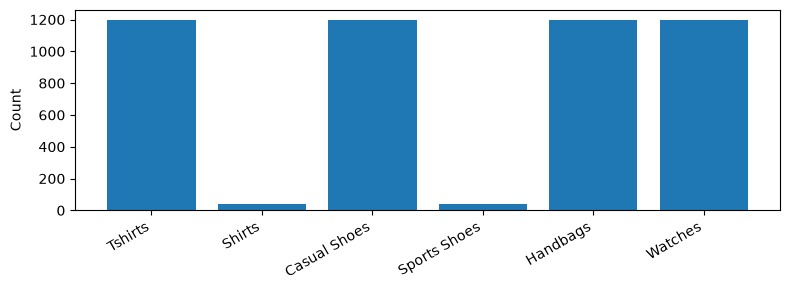

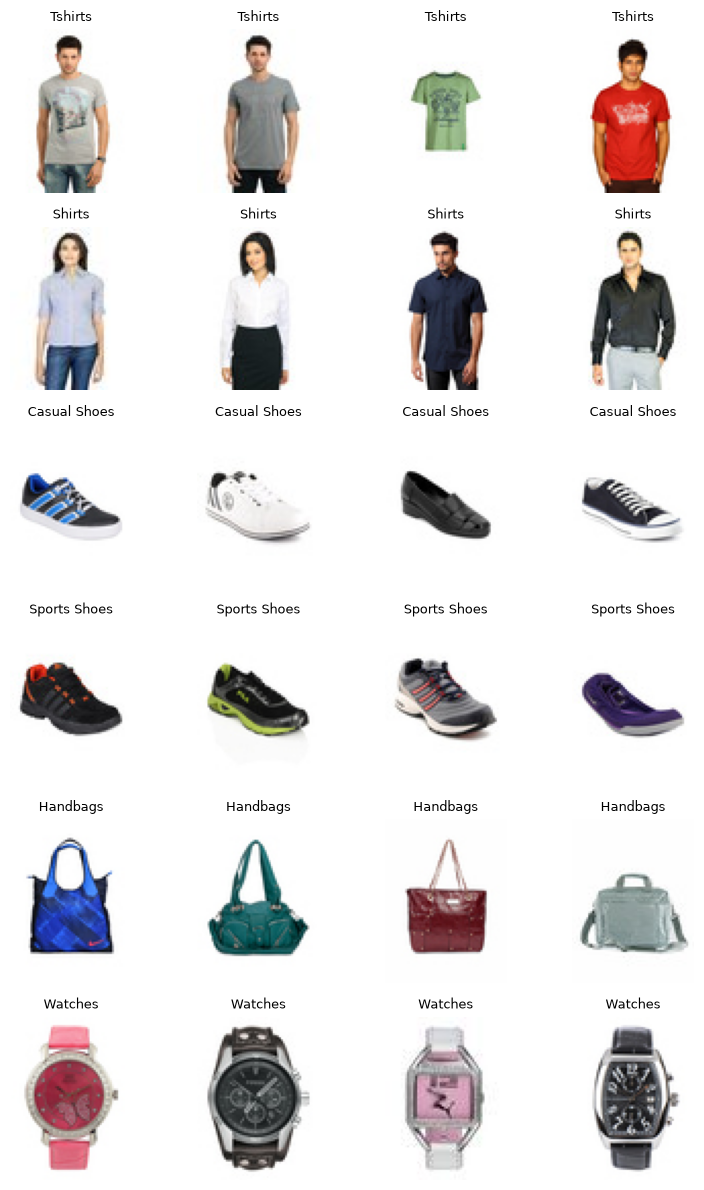

In [6]:
# 수정 금지
# 데이터 접근 예시입니다.

with np.load(data_path, allow_pickle=False) as data:
    image_0 = data['train_images'][0]
    label_0 = data['train_labels'][0]

print('0번 이미지:', type(image_0), image_0.shape, image_0.dtype)
print('0번 라벨:', label_0, '클래스 이름:', class_names[int(label_0)])


def count_class_images(dataset_path):
    """prepared.npz와 classes.json을 읽어 학습 이미지 수를 집계합니다."""
    dataset_path = Path(dataset_path)
    with dataset_path.with_name('classes.json').open(encoding='utf-8') as file:
        names = json.load(file)
    with np.load(dataset_path, allow_pickle=False) as data:
        labels = data['train_labels']

    counts = {name: 0 for name in names}
    for label in labels:
        counts[names[int(label)]] += 1
    return counts


class_counts = count_class_images(data_path)
print(class_counts)

plt.figure(figsize=(8, 3))
plt.bar(class_names, [class_counts[name] for name in class_names])
plt.xticks(rotation=30, ha='right')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(num_classes, 4, figsize=(8, num_classes * 2), squeeze=False)
for label in range(num_classes):
    for axis in axes[label]:
        axis.axis('off')
    examples = np.flatnonzero(train_labels == label)[:4]
    for column, index in enumerate(examples):
        axes[label, column].imshow(train_images[index])
        axes[label, column].set_title(class_names[label], fontsize=9)
plt.tight_layout()
plt.show()


# **답안 작성 셀 - 데이터 전처리**

> 데이터와 관련된 성능 저하에 관한 영향에 대해서 조사했더니, 다음과 같은 경우들이 있는 것을 확인하였다. 

> - **데이터 부족**: 학습에 필요한 데이터가 부족하거나 특정 상황의 사례가 충분하지 않음.
> - **클래스 불균형**: 일부 클래스에 데이터가 편중되어 데이터가 적은 클래스의 특성을 충분히 학습하지 못함.
> - **라벨 오류**: 잘못된 정답이 부여되거나 동일한 기준으로 라벨링되지 않음.
> - **낮은 데이터 품질**: 이미지 손상, 흐림, 가림, 낮은 해상도 등으로 분류에 필요한 정보를 확인하기 어려움.
> - **데이터 다양성 부족**: 촬영 각도, 조명, 배경, 대상의 형태 등이 제한적이어서 새로운 조건에 대응하기 어려움.
> - **데이터 분포 차이**: 학습 데이터와 평가·실제 서비스 데이터의 특성이 달라 학습한 패턴이 잘 적용되지 않음.
> - **부적절한 전처리**: 크기 조정, 정규화, 색상 처리 등에서 필요한 정보가 손실되거나 모델이 기대하는 입력 형식과 달라짐.
> - **부적절한 데이터 증강**: 증강이 실제 환경을 반영하지 못하거나 대상을 과도하게 변형하여 정답의 의미를 훼손함.
> - **중복·유사 데이터 편중**: 데이터 수에 비해 새로운 정보가 적어 특정 사례를 반복적으로 학습함.
> - **데이터 분할 문제**: 학습·검증 데이터가 전체 특성을 고르게 반영하지 못해 성능이 낮거나 불안정하게 측정됨.
> - **데이터 누수**: 평가 데이터나 정답을 유추할 수 있는 정보가 학습에 포함되어 평가 성능과 실제 성능 사이에 차이가 발생함.
> - **클래스 정의의 모호함**: 클래스 간 구분 기준이 불명확하거나 서로 겹쳐 일관된 학습과 평가가 어려움.
> - **입력 정보의 한계**: 정답을 구분하는 데 필요한 특징이 입력 데이터에 없거나 충분히 드러나지 않음.
> - **우연한 단서에 대한 편향**: 대상의 본질적인 특징보다 배경, 워터마크, 촬영 방식 등 정답과 우연히 연결된 단서를 학습함.

> 위에서 확인한 데이터 분석에 따르면, 위 문제 중 하나의 문제가 가장 의심된다. \
> 이제 감을 잡았다. 해결책을 구현하기만 하면 될 것 같다. \
> 데이터 증강은 데이터에 변화를 주어 마치 새로운 데이터를 합성한 것과 같은 효과를 줄 수 있으니, 이를 활용하여 문제를 해결하자!


### 문제 목표
위에서 확인한 데이터 분석을 바탕으로, 현재 학습 데이터셋의 문제를 파악하고, 그 문제 해결을 위한 적절한 전처리 및 변환을 설계하세요.  \
아래 한 셀에 있는 **`train_transform`과 `processing_training_data()`**에서 필요한 부분을 적절히 수정하세요. \
아래 `processing_training_data` 함수 예시를 보고, 데이터 변환(증강)이 적용하는 전략을 구현하는 함수입니다. 이미지 변환은 해당 항목의 flag가 True일 때만 적용되고, False인 데이터에는 적용되지 않습니다.

`processing_training_data`는 학습에 사용할 원본 인덱스와 각 항목에 적용할 transform을 정하는 flag를 반환합니다. \
아래 `FashionDataset`에서 flag가 어떻게 사용되는지 확인하세요. 이 클래스는 제공 코드이며 수정하면 안 됩니다.

- 제공된 train 안에서만 데이터를 구성하고, 클래스 번호와 정답의 대응을 유지하세요.
- transform의 출력은 정규화된 `torch.float32` 텐서이며 크기는 `(3, 80, 60)`으로 유지하세요.
- 아래 제공된 정규화 값과 `eval_transform`, 검증 데이터, 모델·학습·평가 코드는 변경하지 마세요.



### 공식 문서

- [torchvision Transform 종류와 사용법](docs/pages/docs.pytorch.org/vision_0.26_transforms--d97759c5de81.html)
- [Transform 적용 결과를 그림으로 비교하는 예제](docs/pages/docs.pytorch.org/vision_0.26_auto_examples_transforms_plot_transforms_illustrations--0d046f058aa3.html)

이 노트북은 `torchvision.transforms`를 사용합니다. 문서의 V1 API Reference를 참고하세요. 시각화 예제에는 `transforms.v2` 코드가 있으므로 import와 사용법을 구분해 참고하세요.


In [7]:
# 수정 금지
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean, std),
])


In [8]:
# 수정 가능
# train_transform과 processing_training_data는 자유롭게 수정해도 됩니다.
# 다만, train_transform과 processing_training_data의 이름과 매개변수는 변경하지 마세요.

train_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean, std),
])


def processing_training_data(labels):
    """학습에 사용할 인덱스와 항목별 transform 적용 여부를 반환합니다.

    labels: 원본 train의 1차원 정수 라벨 배열.
    반환: (indices, augment_flags)
        indices: 원본 train 범위 안의 1차원 정수 배열.
        augment_flags: indices와 같은 길이의 1차원 bool 배열.
            True인 항목에는 train_transform, False인 항목에는 eval_transform을 적용합니다.

    예시 (반환 형식 설명용이며, 균형을 맞춘 정답 예시는 아닙니다):
        labels = np.array([0, 0, 1, 2])
        indices = np.array([0, 2, 2], dtype=int)
        augment_flags = np.array([False, False, True], dtype=bool)

        위 두 배열을 반환했다면 원본 0번, 2번, 2번 이미지를 학습에 사용합니다.
        각 항목의 정답은 labels[indices], 즉 [0, 1, 1]입니다.
        앞의 두 항목에는 eval_transform, 마지막 항목에는 train_transform을 적용합니다.

    indices는 클래스 번호가 아니라 원본 이미지 번호입니다. 같은 번호를 반복해도 됩니다.
    두 반환 배열은 같은 위치끼리 짝을 이룹니다. False도 학습에 사용하되 증강은 하지 않습니다.
    True인 항목은 이미지 파일을 미리 만드는 대신, Dataset에서 읽을 때 train_transform을 적용합니다.
    """
    ### 아래 코드를 수정하세요 ###
    indices = np.array(range(len(labels)), dtype=int)
    augment_flags = np.array([False] * len(labels), dtype=bool)
    return indices, augment_flags



In [9]:
# 수정 금지
# Dataset은 제공 코드입니다. flag가 사용되는 위치를 확인하세요.

class FashionDataset(Dataset):
    def __init__(self, images, labels, augment_flags=None):
        self.images = images
        self.labels = labels
        self.augment_flags = augment_flags

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = self.images[index]
        if self.augment_flags is not None and self.augment_flags[index]:
            image = train_transform(image)
        else:
            image = eval_transform(image)
        return image, int(self.labels[index])

In [10]:
# 수정 금지
# 아래 검사를 통과하면, 이어지는 학습·평가 셀을 실행해 결과를 확인하세요.

train_indices, augment_flags = processing_training_data(train_labels)
train_indices = np.asarray(train_indices)
augment_flags = np.asarray(augment_flags)
assert train_indices.ndim == 1, '인덱스는 1차원 배열이어야 합니다.'
assert augment_flags.ndim == 1, '증강 여부는 1차원 배열이어야 합니다.'
assert len(train_indices) > 0, '학습 이미지를 하나 이상 선택하세요.'
assert len(train_indices) == len(augment_flags), '인덱스와 증강 여부의 길이를 맞추세요.'
assert np.issubdtype(train_indices.dtype, np.integer), '인덱스는 정수여야 합니다.'
assert augment_flags.dtype == bool, '증강 여부는 True 또는 False여야 합니다.'
assert train_indices.min() >= 0, '음수 인덱스는 사용할 수 없습니다.'
assert train_indices.max() < len(train_labels), '원본 train 범위를 벗어난 인덱스입니다.'

print('선택한 학습 항목:', len(train_indices), '증강할 항목:', int(augment_flags.sum()))


선택한 학습 항목: 4880 증강할 항목: 0


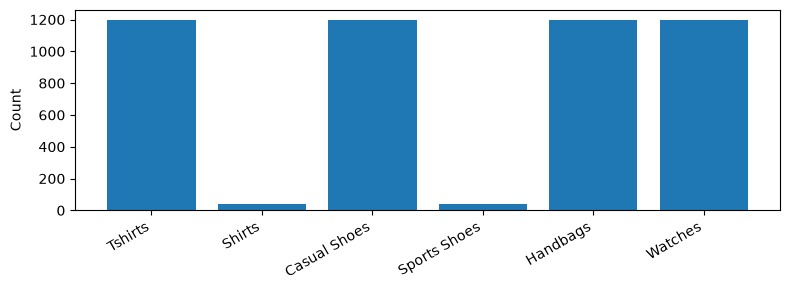

In [11]:
# 수정 금지
# 전처리 후 분포를 확인하는 제공 helper입니다.

def plot_class_counts(labels):
    plt.figure(figsize=(8, 3))
    plt.hist(labels, bins=np.arange(num_classes + 1) - 0.5, rwidth=0.8)
    plt.xticks(range(num_classes), class_names, rotation=30, ha='right')
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()


plot_class_counts(train_labels[train_indices])


## 고정 Linear Probing

여기 이후 코드는 수정하지 않습니다.

TinyViT 모델을 Linear Probing 방식으로 학습하며, 하이퍼파라미터는 고정된 채로 진행합니다.\
macro-F1을 이용해 최종 성능을 확인합니다.\
최하단 셀의 `[Final] Validation macro-F1`에 출력되는 Validation macro-F1 score을 기준으로 성능 관련 점수가 부과될 예정입니다. 

기준은 아래와 같습니다. 
- High-level: 0.75 초과
- Mid-level: 0.60 초과 0.75 이하
- Low-level: 0.60 이하


In [12]:
# 수정 금지

batch_size = 64
learning_rate = 0.0003
epochs = 10
output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)
checkpoint = output_dir / f'P1_1_{student_id}.pt'


In [13]:
# 수정 금지

from safetensors.torch import load_file
from torch.nn import functional as F


def load_pretrained_weights(model):
    """제공된 로컬 가중치를 읽고 상대 위치 bias만 입력 크기에 맞게 보간합니다."""
    path = Path('tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors')
    if not path.is_file():
        raise FileNotFoundError(
            f'사전학습 가중치 파일을 찾을 수 없습니다: {path.resolve()}\n'
            '제공된 가중치 파일을 노트북과 같은 폴더에 두고, 작업 폴더를 해당 폴더로 맞추세요.'
        )
    weights = load_file(str(path))
    target = model.state_dict()
    for name, value in weights.items():
        if name.endswith('attention_biases') and value.shape != target[name].shape:
            num_heads, length = value.shape
            old_window = int(length ** 0.5)
            new_window = int(target[name].shape[1] ** 0.5)
            weights[name] = F.interpolate(
                value.float().reshape(1, num_heads, old_window, old_window),
                size=(new_window, new_window),
                mode='bicubic', antialias=True,
            ).reshape(num_heads, new_window * new_window)
    model.load_state_dict(weights, strict=True)


class LinearProbe(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = timm.create_model(
            'tiny_vit_5m_224.dist_in22k_ft_in1k',
            pretrained=False, num_classes=1000, window_sizes=(3, 3, 5, 3),
        )
        load_pretrained_weights(self.backbone)
        self.backbone.reset_classifier(num_classes)
        self.backbone.requires_grad_(False)
        self.backbone.head.fc.requires_grad_(True)

    def forward(self, x):
        self.backbone.eval()
        with torch.no_grad():
            features = self.backbone.forward_features(x)
            features = self.backbone.forward_head(features, pre_logits=True)
        return self.backbone.head.fc(features)


In [14]:
# 수정 금지

def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss = 0
    sample_count = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        total_loss += loss.item() * len(labels)
        sample_count += len(labels)
    return total_loss / sample_count


def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0
    predictions, targets = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            total_loss += loss_fn(logits, labels).item() * len(labels)
            predictions.extend(logits.argmax(1).cpu().tolist())
            targets.extend(labels.cpu().tolist())
    class_f1 = f1_score(
        targets, predictions, labels=list(range(num_classes)), average=None, zero_division=0
    )
    return total_loss / len(targets), float(class_f1.mean()), class_f1


In [15]:
# 수정 금지

train_dataset = FashionDataset(
    train_images[train_indices], train_labels[train_indices], augment_flags
)
val_dataset = FashionDataset(val_images, val_labels)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)


In [16]:
# 수정 금지

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
model = LinearProbe().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
loss_fn = nn.CrossEntropyLoss()
best_f1 = -1
history = []
class_f1_history = []
started = time.perf_counter()

for epoch in range(epochs):
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)
    val_loss, val_f1, val_class_f1 = evaluate(model, val_loader, loss_fn)
    class_f1_history.append(val_class_f1.tolist())
    history.append({
        'epoch': epoch + 1,
        'train_loss': train_loss,
        'val_loss': val_loss,
        'val_f1': val_f1,
    })
    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(model.state_dict(), checkpoint)
    print(f'{epoch + 1}/{epochs}  학습 Loss: {train_loss:.4f}  검증 F1: {val_f1:.4f}')

print(f'학습 시간: {time.perf_counter() - started:.1f}초')


1/10  학습 Loss: 1.3799  검증 F1: 0.4737


2/10  학습 Loss: 1.0102  검증 F1: 0.4899


3/10  학습 Loss: 0.8126  검증 F1: 0.4959


4/10  학습 Loss: 0.6867  검증 F1: 0.5054


5/10  학습 Loss: 0.5999  검증 F1: 0.5102


6/10  학습 Loss: 0.5361  검증 F1: 0.5122


7/10  학습 Loss: 0.4876  검증 F1: 0.5151


8/10  학습 Loss: 0.4493  검증 F1: 0.5154


9/10  학습 Loss: 0.4171  검증 F1: 0.5211


10/10  학습 Loss: 0.3904  검증 F1: 0.5199
학습 시간: 20.5초


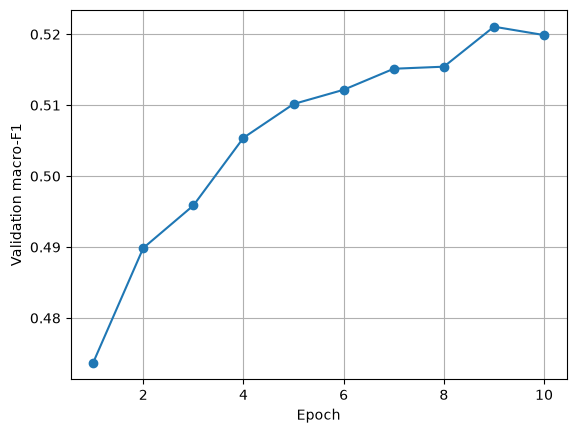

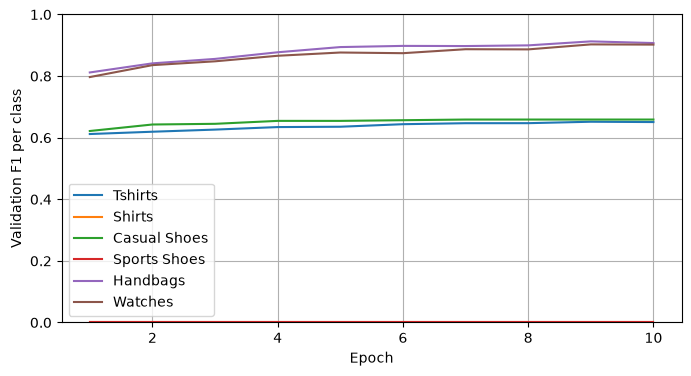

In [17]:
# 수정 금지

epoch_numbers = [row['epoch'] for row in history]
plt.plot(epoch_numbers, [row['val_f1'] for row in history], marker='o')
plt.xlabel('Epoch')
plt.ylabel('Validation macro-F1')
plt.grid()
plt.show()

plt.figure(figsize=(8, 4))
for label, name in enumerate(class_names):
    scores = [row[label] for row in class_f1_history]
    plt.plot(epoch_numbers, scores, label=name)
plt.xlabel('Epoch')
plt.ylabel('Validation F1 per class')
plt.ylim(0, 1)
plt.legend()
plt.grid()
plt.show()


In [18]:
# 수정 금지

model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
val_loss, val_f1, val_class_f1 = evaluate(model, val_loader, loss_fn)
print(f'[Final] Validation macro-F1: {val_f1:.4f}')
print('Class           Validation F1')
for name, score in zip(class_names, val_class_f1):
    print(f'{name:14s} {score:13.4f}')


[Final] Validation macro-F1: 0.5211
Class           Validation F1
Tshirts               0.6518
Shirts                0.0000
Casual Shoes          0.6589
Sports Shoes          0.0000
Handbags              0.9127
Watches               0.9029


## 제출

아래 파일들을 제출하세요.
- 완성한 노트북 `.ipynb`
- Best 체크포인트 `outputs/P1_1_<수험번호>.pt`

파일명에는 첫 셀의 수험번호가 자동으로 들어갑니다. 따로 이름을 바꿀 필요가 없습니다.

- 실제로 실행하는데 사용된 체크포인트 결과만 제출하세요.
- 실제로 실행한 validation 결과를 노트북에 남기세요.


<details>
<summary>코드 라이선스 고지</summary>

수정하여 사용한 PyTorch 문서 코드의 사용 고지입니다. 과제의 평가 기준과는 무관합니다.

```text
BSD 3-Clause License

Copyright (c) 2017-2022, Pytorch contributors
All rights reserved.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

* Redistributions of source code must retain the above copyright notice, this
  list of conditions and the following disclaimer.
* Redistributions in binary form must reproduce the above copyright notice,
  this list of conditions and the following disclaimer in the documentation
  and/or other materials provided with the distribution.
* Neither the name of the copyright holder nor the names of its
  contributors may be used to endorse or promote products derived from
  this software without specific prior written permission.
THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS AND CONTRIBUTORS "AS IS"
AND ANY EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR PURPOSE ARE
DISCLAIMED. IN NO EVENT SHALL THE COPYRIGHT HOLDER OR CONTRIBUTORS BE LIABLE
FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL, EXEMPLARY, OR CONSEQUENTIAL
DAMAGES (INCLUDING, BUT NOT LIMITED TO, PROCUREMENT OF SUBSTITUTE GOODS OR
SERVICES; LOSS OF USE, DATA, OR PROFITS; OR BUSINESS INTERRUPTION) HOWEVER
CAUSED AND ON ANY THEORY OF LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY,
OR TORT (INCLUDING NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE
OF THIS SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
```



### 모델 코드 사용 고지

TinyViT 구성 블록은 Microsoft TinyViT 및 timm의 구현을 교육용으로 수정했습니다. 이 노트북에서는 TinyViT 5M, 직사각형 입력, 작은 window, 명시적인 stage별 forward와 가중치 로딩을 사용합니다.

Microsoft TinyViT: Copyright (c) Microsoft Corporation. MIT License.

timm: Copyright 2019 Ross Wightman. Apache License, Version 2.0.

```text
MIT License

Copyright (c) Microsoft Corporation.

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
```

```text
Apache License
                           Version 2.0, January 2004
                        http://www.apache.org/licenses/

   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION

   1. Definitions.

      "License" shall mean the terms and conditions for use, reproduction,
      and distribution as defined by Sections 1 through 9 of this document.

      "Licensor" shall mean the copyright owner or entity authorized by
      the copyright owner that is granting the License.

      "Legal Entity" shall mean the union of the acting entity and all
      other entities that control, are controlled by, or are under common
      control with that entity. For the purposes of this definition,
      "control" means (i) the power, direct or indirect, to cause the
      direction or management of such entity, whether by contract or
      otherwise, or (ii) ownership of fifty percent (50%) or more of the
      outstanding shares, or (iii) beneficial ownership of such entity.

      "You" (or "Your") shall mean an individual or Legal Entity
      exercising permissions granted by this License.

      "Source" form shall mean the preferred form for making modifications,
      including but not limited to software source code, documentation
      source, and configuration files.

      "Object" form shall mean any form resulting from mechanical
      transformation or translation of a Source form, including but
      not limited to compiled object code, generated documentation,
      and conversions to other media types.

      "Work" shall mean the work of authorship, whether in Source or
      Object form, made available under the License, as indicated by a
      copyright notice that is included in or attached to the work
      (an example is provided in the Appendix below).

      "Derivative Works" shall mean any work, whether in Source or Object
      form, that is based on (or derived from) the Work and for which the
      editorial revisions, annotations, elaborations, or other modifications
      represent, as a whole, an original work of authorship. For the purposes
      of this License, Derivative Works shall not include works that remain
      separable from, or merely link (or bind by name) to the interfaces of,
      the Work and Derivative Works thereof.

      "Contribution" shall mean any work of authorship, including
      the original version of the Work and any modifications or additions
      to that Work or Derivative Works thereof, that is intentionally
      submitted to Licensor for inclusion in the Work by the copyright owner
      or by an individual or Legal Entity authorized to submit on behalf of
      the copyright owner. For the purposes of this definition, "submitted"
      means any form of electronic, verbal, or written communication sent
      to the Licensor or its representatives, including but not limited to
      communication on electronic mailing lists, source code control systems,
      and issue tracking systems that are managed by, or on behalf of, the
      Licensor for the purpose of discussing and improving the Work, but
      excluding communication that is conspicuously marked or otherwise
      designated in writing by the copyright owner as "Not a Contribution."

      "Contributor" shall mean Licensor and any individual or Legal Entity
      on behalf of whom a Contribution has been received by Licensor and
      subsequently incorporated within the Work.

   2. Grant of Copyright License. Subject to the terms and conditions of
      this License, each Contributor hereby grants to You a perpetual,
      worldwide, non-exclusive, no-charge, royalty-free, irrevocable
      copyright license to reproduce, prepare Derivative Works of,
      publicly display, publicly perform, sublicense, and distribute the
      Work and such Derivative Works in Source or Object form.

   3. Grant of Patent License. Subject to the terms and conditions of
      this License, each Contributor hereby grants to You a perpetual,
      worldwide, non-exclusive, no-charge, royalty-free, irrevocable
      (except as stated in this section) patent license to make, have made,
      use, offer to sell, sell, import, and otherwise transfer the Work,
      where such license applies only to those patent claims licensable
      by such Contributor that are necessarily infringed by their
      Contribution(s) alone or by combination of their Contribution(s)
      with the Work to which such Contribution(s) was submitted. If You
      institute patent litigation against any entity (including a
      cross-claim or counterclaim in a lawsuit) alleging that the Work
      or a Contribution incorporated within the Work constitutes direct
      or contributory patent infringement, then any patent licenses
      granted to You under this License for that Work shall terminate
      as of the date such litigation is filed.

   4. Redistribution. You may reproduce and distribute copies of the
      Work or Derivative Works thereof in any medium, with or without
      modifications, and in Source or Object form, provided that You
      meet the following conditions:

      (a) You must give any other recipients of the Work or
          Derivative Works a copy of this License; and

      (b) You must cause any modified files to carry prominent notices
          stating that You changed the files; and

      (c) You must retain, in the Source form of any Derivative Works
          that You distribute, all copyright, patent, trademark, and
          attribution notices from the Source form of the Work,
          excluding those notices that do not pertain to any part of
          the Derivative Works; and

      (d) If the Work includes a "NOTICE" text file as part of its
          distribution, then any Derivative Works that You distribute must
          include a readable copy of the attribution notices contained
          within such NOTICE file, excluding those notices that do not
          pertain to any part of the Derivative Works, in at least one
          of the following places: within a NOTICE text file distributed
          as part of the Derivative Works; within the Source form or
          documentation, if provided along with the Derivative Works; or,
          within a display generated by the Derivative Works, if and
          wherever such third-party notices normally appear. The contents
          of the NOTICE file are for informational purposes only and
          do not modify the License. You may add Your own attribution
          notices within Derivative Works that You distribute, alongside
          or as an addendum to the NOTICE text from the Work, provided
          that such additional attribution notices cannot be construed
          as modifying the License.

      You may add Your own copyright statement to Your modifications and
      may provide additional or different license terms and conditions
      for use, reproduction, or distribution of Your modifications, or
      for any such Derivative Works as a whole, provided Your use,
      reproduction, and distribution of the Work otherwise complies with
      the conditions stated in this License.

   5. Submission of Contributions. Unless You explicitly state otherwise,
      any Contribution intentionally submitted for inclusion in the Work
      by You to the Licensor shall be under the terms and conditions of
      this License, without any additional terms or conditions.
      Notwithstanding the above, nothing herein shall supersede or modify
      the terms of any separate license agreement you may have executed
      with Licensor regarding such Contributions.

   6. Trademarks. This License does not grant permission to use the trade
      names, trademarks, service marks, or product names of the Licensor,
      except as required for reasonable and customary use in describing the
      origin of the Work and reproducing the content of the NOTICE file.

   7. Disclaimer of Warranty. Unless required by applicable law or
      agreed to in writing, Licensor provides the Work (and each
      Contributor provides its Contributions) on an "AS IS" BASIS,
      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or
      implied, including, without limitation, any warranties or conditions
      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A
      PARTICULAR PURPOSE. You are solely responsible for determining the
      appropriateness of using or redistributing the Work and assume any
      risks associated with Your exercise of permissions under this License.

   8. Limitation of Liability. In no event and under no legal theory,
      whether in tort (including negligence), contract, or otherwise,
      unless required by applicable law (such as deliberate and grossly
      negligent acts) or agreed to in writing, shall any Contributor be
      liable to You for damages, including any direct, indirect, special,
      incidental, or consequential damages of any character arising as a
      result of this License or out of the use or inability to use the
      Work (including but not limited to damages for loss of goodwill,
      work stoppage, computer failure or malfunction, or any and all
      other commercial damages or losses), even if such Contributor
      has been advised of the possibility of such damages.

   9. Accepting Warranty or Additional Liability. While redistributing
      the Work or Derivative Works thereof, You may choose to offer,
      and charge a fee for, acceptance of support, warranty, indemnity,
      or other liability obligations and/or rights consistent with this
      License. However, in accepting such obligations, You may act only
      on Your own behalf and on Your sole responsibility, not on behalf
      of any other Contributor, and only if You agree to indemnify,
      defend, and hold each Contributor harmless for any liability
      incurred by, or claims asserted against, such Contributor by reason
      of your accepting any such warranty or additional liability.

   END OF TERMS AND CONDITIONS

   APPENDIX: How to apply the Apache License to your work.

      To apply the Apache License to your work, attach the following
      boilerplate notice, with the fields enclosed by brackets "{}"
      replaced with your own identifying information. (Don't include
      the brackets!)  The text should be enclosed in the appropriate
      comment syntax for the file format. We also recommend that a
      file or class name and description of purpose be included on the
      same "printed page" as the copyright notice for easier
      identification within third-party archives.

   Copyright 2019 Ross Wightman

   Licensed under the Apache License, Version 2.0 (the "License");
   you may not use this file except in compliance with the License.
   You may obtain a copy of the License at

       http://www.apache.org/licenses/LICENSE-2.0

   Unless required by applicable law or agreed to in writing, software
   distributed under the License is distributed on an "AS IS" BASIS,
   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
   See the License for the specific language governing permissions and
   limitations under the License.
```

</details>
